# SAM2 – standard run and fine-tuning on FoodSeg103

**Standard pipeline** for both runs: SAM 2.1 (`hiera_large`) with `SAM2AutomaticMaskGenerator` at its
**default settings** (32×32 point grid, `pred_iou_thresh=0.8`, `stability_score_thresh=0.95`, `box_nms_thresh=0.7`),

**Fine-tuning** teaches SAM2 what a FoodSeg103 "object" is. The image encoder stays frozen (fits 8 GB);

Outputs: `outputs/sam2_standard_test.pkl` (zero-shot) and `outputs/sam2_finetuned_test.pkl` (fine-tuned) for
`compare_models.ipynb`

## 1 Library

In [2]:
import time, json, random

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pycocotools import mask as mask_utils

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator

# shared dataset access + evaluation (playground/foodseg_common.py)
import foodseg_common as fc

print('Torch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

Torch version: 2.10.0
CUDA available: True


## 2 Configuration

In [3]:
SAM2_MODELS = {
    'large': ('configs/sam2.1/sam2.1_hiera_l.yaml', fc.MODELS_DIR / 'sam2.1_hiera_large.pt'),
    'small': ('configs/sam2.1/sam2.1_hiera_s.yaml', fc.MODELS_DIR / 'sam2.1_hiera_small.pt'),
}
MODEL_SIZE = 'small'
SAM2_CONFIG, SAM2_CHECKPOINT = SAM2_MODELS[MODEL_SIZE]

SPLIT     = 'test'
LIMIT     = None     # e.g. 20 for a quick trial; None = full test split
MAX_SIDE  = 1500     # larger images are downscaled for the generator (masks resized back) to fit 8 GB
SCORE_THR = 0.0      # standard run: keep every mask the generator returns
SEED      = 42
RUN_BASELINE = True  # zero-shot standard run (section 4-5); resumes from its cache if already done

# fine-tuning
FT = dict(
    epochs        = 3,
    lr            = 5e-5,
    weight_decay  = 1e-4,
    accum_steps   = 4,       # images per optimizer step
    pos_per_image = 8,       # food regions prompted per image (one random point each)
    neg_per_image = 2,       # background points per image (IoU target 0)
    train_limit   = None,    # e.g. 200 for a quick trial; None = full train split
    val_limit     = 150,     # fixed val subset scored after every epoch
    min_area      = fc.MIN_AREA,
)
FT_DIR = fc.PLAYGROUND / 'runs' / 'sam2_ft'
FT_DIR.mkdir(parents=True, exist_ok=True)
FT_CKPT = FT_DIR / f'sam2_{MODEL_SIZE}_decoder_best.pt'

device   = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT_ROOT = fc.OUT_ROOT
OUT_ROOT.mkdir(parents=True, exist_ok=True)
BASE_CACHE = OUT_ROOT / f'sam2_standard_{SPLIT}.pkl'
FT_CACHE   = OUT_ROOT / f'sam2_finetuned_{SPLIT}.pkl'

print('SAM2 config:', SAM2_CONFIG)
print('SAM2 checkpoint:', SAM2_CHECKPOINT, '| exists:', SAM2_CHECKPOINT.exists())
print('Device:', device)
print('Fine-tune dir:', FT_DIR)
for name in fc.SPLITS:
    print(f'  {name}: {len(fc.read_split_ids(name))} ids')

SAM2 config: configs/sam2.1/sam2.1_hiera_s.yaml
SAM2 checkpoint: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\models\sam2.1_hiera_small.pt | exists: True
Device: cuda
Fine-tune dir: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\sam2_ft
  train: 4982 ids
  val: 1067 ids
  test: 1069 ids


## 3 Model & automatic mask generator (default settings)

In [4]:
if not SAM2_CHECKPOINT.exists():
    raise FileNotFoundError(f'SAM 2 checkpoint not found at: {SAM2_CHECKPOINT}')

if device == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

sam2_model = build_sam2(SAM2_CONFIG, str(SAM2_CHECKPOINT), device=device, apply_postprocessing=False)
mask_generator = SAM2AutomaticMaskGenerator(sam2_model, output_mode='coco_rle')   # library defaults

print('Mask generator settings:')
print('  points_per_side:', int(np.sqrt(len(mask_generator.point_grids[0]))))
for k in ('pred_iou_thresh', 'stability_score_thresh', 'box_nms_thresh'):
    print(f'  {k}: {getattr(mask_generator, k)}')

Mask generator settings:
  points_per_side: 32
  pred_iou_thresh: 0.8
  stability_score_thresh: 0.95
  box_nms_thresh: 0.7


In [5]:
def _resize_rle(rle, h, w):
    """Nearest-neighbour resize of an RLE mask to (h, w)."""
    m = cv2.resize(mask_utils.decode(rle), (w, h), interpolation=cv2.INTER_NEAREST)
    return mask_utils.encode(np.asfortranarray(m))


def run_standard(generator, split, ids, cache_path, model_name, save_every=25):
    """Run a mask generator over ids -> foodseg_common prediction cache (scores = predicted_iou), resumable."""
    preds, meta = fc.load_preds(cache_path) if cache_path.exists() else ({}, {})
    secs = meta.get('secs', {})

    def _meta():
        return dict(model=model_name, score_thr=SCORE_THR, max_side=MAX_SIDE, secs=secs,
                    sec_per_image=float(np.mean(list(secs.values()))) if secs else np.nan)

    todo = [sid for sid in ids if sid not in preds]
    for n, sid in enumerate(tqdm(todo, desc=f'{model_name} {split}')):
        img = fc.load_rgb(fc.image_path(split, sid))
        h, w = img.shape[:2]
        scale = min(1.0, MAX_SIDE / max(h, w))
        if scale < 1.0:
            img = cv2.resize(img, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)

        t0 = time.time()
        with torch.inference_mode(), torch.autocast(device, dtype=torch.bfloat16, enabled=device == 'cuda'):
            anns = generator.generate(img)
        secs[sid] = time.time() - t0

        anns = sorted(anns, key=lambda a: -a['predicted_iou'])
        rles = [a['segmentation'] for a in anns]
        if scale < 1.0:
            rles = [_resize_rle(r, h, w) for r in rles]
        preds[sid] = dict(h=h, w=w, rle=rles,
                          scores=np.array([a['predicted_iou'] for a in anns], dtype=np.float32))

        if (n + 1) % save_every == 0:
            fc.save_preds(preds, cache_path, _meta())
    fc.save_preds(preds, cache_path, _meta())
    return {sid: preds[sid] for sid in ids}, _meta()


test_ids = fc.read_split_ids(SPLIT)
test_ids = test_ids[:LIMIT] if LIMIT else test_ids
print('Test images:', len(test_ids))

Test images: 1069


## 4 Baseline: zero-shot test inference

Pretrained weights, default generator. Cached to `outputs/sam2_standard_test.pkl` every 25 images, so an
interrupted run resumes where it stopped. Set `RUN_BASELINE = False` to skip.

In [6]:
if RUN_BASELINE:
    base_preds, base_meta = run_standard(mask_generator, SPLIT, test_ids, BASE_CACHE,
                                         f'SAM2.1 hiera_{MODEL_SIZE} AMG (standard defaults)')
    print(f'{len(base_preds)} images, {base_meta["sec_per_image"]:.2f}s/img, '
          f'{np.mean([len(p["rle"]) for p in base_preds.values()]):.1f} masks/img')
else:
    base_preds = None
    print('Baseline skipped.')

SAM2.1 hiera_small AMG (standard defaults) test:   0%|          | 0/644 [00:00<?, ?it/s]

1069 images, 2.78s/img, 15.2 masks/img


## 5 Baseline evaluation

In [7]:
if base_preds is not None:
    base_m = fc.evaluate(base_preds, SPLIT, score_thr=SCORE_THR)
    base_result = dict(model=base_meta['model'], sec_per_image=base_meta['sec_per_image'], **base_m)
    (OUT_ROOT / 'sam2_standard_test_result.json').write_text(json.dumps(base_result, indent=2))
    print('Zero-shot test results:')
    for k, v in base_result.items():
        print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Zero-shot test results:
  model: SAM2.1 hiera_small AMG (standard defaults)
  sec_per_image: 2.7798
  n_images: 1069
  score_thr: 0.0000
  AP: 0.0448
  AP50: 0.0701
  AP75: 0.0415
  AP_small: 0.0016
  AP_medium: 0.0182
  AP_large: 0.0562
  AR1: 0.0703
  AR10: 0.1905
  AR100: 0.2043
  precision@50: 0.0668
  recall@50: 0.2762
  f1@50: 0.1075
  precision@75: 0.0481
  recall@75: 0.1988
  f1@75: 0.0774
  gt_coverage_mean: 0.3208
  gt_coverage_at50: 0.2762
  fg_iou_mean: 0.3383
  fg_iou_pixel: 0.3284
  preds_per_image: 15.1590


## 6 Fine-tuning helpers

Prompts are encoded and decoded exactly as `SAM2ImagePredictor._predict` does for the mask generator
(single positive point, `multimask_output=True`). Losses are computed on the 256×256 low-res logits;
SAM2 resizes every image to a 1024×1024 square, so a 256×256 resize of the GT region is pixel-aligned with them.

In [8]:
LOW_RES = 256


def sample_prompts(label_mask, rng, n_pos, n_neg, min_area):
    """Random points inside food regions (target = region) and on background (target = empty)."""
    points, targets, is_pos = [], [], []
    inst = fc.gt_instances(label_mask, min_area)
    for k in rng.permutation(len(inst))[:n_pos]:
        t = cv2.resize(inst[k].astype(np.uint8), (LOW_RES, LOW_RES), interpolation=cv2.INTER_NEAREST)
        if not t.any():
            continue   # region vanishes at 256x256
        ys, xs = np.nonzero(inst[k])
        j = rng.integers(len(xs))
        points.append((xs[j], ys[j])); targets.append(t); is_pos.append(True)
    ys, xs = np.nonzero(label_mask == 0)
    if n_neg and len(xs):
        for j in rng.integers(len(xs), size=n_neg):
            points.append((xs[j], ys[j])); targets.append(np.zeros((LOW_RES, LOW_RES), np.uint8)); is_pos.append(False)
    return points, targets, is_pos


def prompt_forward(predictor, points):
    """Single-point prompts on the image set in predictor -> (N, 3, 256, 256) logits, (N, 3) IoU predictions."""
    pts = np.asarray(points, dtype=np.float32)[:, None, :]          # N x 1 x 2 (x, y) in original pixels
    lbl = np.ones((len(points), 1), dtype=np.int32)
    _, coords, labels, _ = predictor._prep_prompts(pts, lbl, box=None, mask_logits=None, normalize_coords=True)
    sparse, dense = predictor.model.sam_prompt_encoder(points=(coords, labels), boxes=None, masks=None)
    high_res = [f[-1].unsqueeze(0) for f in predictor._features['high_res_feats']]
    low_res, iou_pred, _, _ = predictor.model.sam_mask_decoder(
        image_embeddings=predictor._features['image_embed'][-1].unsqueeze(0),
        image_pe=predictor.model.sam_prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse,
        dense_prompt_embeddings=dense,
        multimask_output=True,
        repeat_image=len(points) > 1,
        high_res_features=high_res,
    )
    return low_res.float(), iou_pred.float()


def ft_loss(low_res, iou_pred, target, is_pos):
    """Best-of-3 BCE + Dice on food regions, MSE between predicted and true IoU on every output."""
    t = target[:, None].expand_as(low_res)
    bce = F.binary_cross_entropy_with_logits(low_res, t, reduction='none').mean((2, 3))
    p = torch.sigmoid(low_res)
    dice = 1 - (2 * (p * t).sum((2, 3)) + 1) / (p.sum((2, 3)) + t.sum((2, 3)) + 1)
    per_output = bce + dice                                          # N x 3

    with torch.no_grad():
        pm = (low_res > 0).float()
        inter = (pm * t).sum((2, 3))
        union = ((pm + t) > 0).float().sum((2, 3))
        true_iou = inter / union.clamp(min=1)
        true_iou[~is_pos] = 0.0                                      # background prompt: no food object

    mask_loss = per_output.min(1).values[is_pos].mean() if is_pos.any() else low_res.sum() * 0
    iou_loss = F.mse_loss(iou_pred, true_iou)
    return mask_loss + iou_loss, true_iou


def set_trainable(model, train):
    """Freeze everything except the prompt encoder and mask decoder."""
    for p in model.parameters():
        p.requires_grad_(False)
    for m in (model.sam_prompt_encoder, model.sam_mask_decoder):
        m.train(train)
        for p in m.parameters():
            p.requires_grad_(train)


def load_prompts(split, sid, rng):
    img = fc.load_rgb(fc.image_path(split, sid))
    lm = fc.load_label_mask(fc.mask_path(split, sid))
    points, targets, is_pos = sample_prompts(lm, rng, FT['pos_per_image'], FT['neg_per_image'], FT['min_area'])
    return img, points, targets, is_pos


@torch.no_grad()
def evaluate_prompts(predictor, split, ids, seed=SEED):
    """Point-prompt quality on a fixed subset: IoU of the top-scored mask, best-of-3 IoU, IoU-head error."""
    rows = dict(top_iou=[], best_iou=[], iou_mae=[], neg_pred_iou=[])
    for i, sid in enumerate(ids):
        img, points, targets, is_pos = load_prompts(split, sid, np.random.default_rng(seed + i))
        if not points:
            continue
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == 'cuda'):
            predictor.set_image(img)
            low_res, iou_pred = prompt_forward(predictor, points)
        tgt = torch.as_tensor(np.stack(targets), dtype=torch.float32, device=device)
        pos = torch.as_tensor(is_pos, device=device)
        _, true_iou = ft_loss(low_res, iou_pred, tgt, pos)
        top = iou_pred.argmax(1)
        if pos.any():
            rows['top_iou'] += true_iou[pos].gather(1, top[pos, None])[:, 0].tolist()
            rows['best_iou'] += true_iou[pos].max(1).values.tolist()
            rows['iou_mae'] += (iou_pred[pos] - true_iou[pos]).abs().mean(1).tolist()
        if (~pos).any():
            rows['neg_pred_iou'] += iou_pred[~pos].max(1).values.tolist()
    return {k: float(np.mean(v)) if v else float('nan') for k, v in rows.items()}


print('Fine-tuning helpers defined.')

Fine-tuning helpers defined.


## 7 Fine-tuning (prompt encoder + mask decoder)

One image per forward pass with up to `pos_per_image + neg_per_image` point prompts, gradients accumulated over
`accum_steps` images. After every epoch a fixed val subset is scored; the epoch with the best `top_iou`
(IoU of the mask the IoU head ranks first – what the generator keeps) is saved to `runs/sam2_ft/`.

In [9]:
rng = np.random.default_rng(SEED)
random.seed(SEED); torch.manual_seed(SEED)

train_ids = fc.read_split_ids('train')
train_ids = train_ids[:FT['train_limit']] if FT['train_limit'] else train_ids
val_ids = sorted(random.Random(SEED).sample(fc.read_split_ids('val'), FT['val_limit']))

predictor = SAM2ImagePredictor(sam2_model)
set_trainable(sam2_model, False)
val0 = evaluate_prompts(predictor, 'val', val_ids)
print('epoch 0 (pretrained) val:', {k: round(v, 4) for k, v in val0.items()})

set_trainable(sam2_model, True)
params = [p for p in sam2_model.parameters() if p.requires_grad]
print(f'trainable parameters: {sum(p.numel() for p in params) / 1e6:.2f} M')
opt = torch.optim.AdamW(params, lr=FT['lr'], weight_decay=FT['weight_decay'])
total_steps = FT['epochs'] * int(np.ceil(len(train_ids) / FT['accum_steps']))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=FT['lr'], total_steps=total_steps, pct_start=0.1)

history = [dict(epoch=0, loss=float('nan'), **val0)]
best = val0['top_iou']
torch.save(dict(epoch=0, prompt_encoder=sam2_model.sam_prompt_encoder.state_dict(),
                mask_decoder=sam2_model.sam_mask_decoder.state_dict(), val=val0, config=FT), FT_CKPT)

for ep in range(1, FT['epochs'] + 1):
    set_trainable(sam2_model, True)
    order = rng.permutation(len(train_ids))
    t0, losses = time.time(), []
    opt.zero_grad(set_to_none=True)
    for n, i in enumerate(tqdm(order, desc=f'epoch {ep}/{FT["epochs"]}')):
        img, points, targets, is_pos = load_prompts('train', train_ids[i], rng)
        if points:
            with torch.autocast(device, dtype=torch.bfloat16, enabled=device == 'cuda'):
                predictor.set_image(img)                     # frozen image encoder (no_grad inside)
                low_res, iou_pred = prompt_forward(predictor, points)
            tgt = torch.as_tensor(np.stack(targets), dtype=torch.float32, device=device)
            pos = torch.as_tensor(is_pos, device=device)
            loss, _ = ft_loss(low_res, iou_pred, tgt, pos)
            (loss / FT['accum_steps']).backward()
            losses.append(loss.item())
        if (n + 1) % FT['accum_steps'] == 0 or n + 1 == len(order):
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step(); sched.step()
            opt.zero_grad(set_to_none=True)

    set_trainable(sam2_model, False)
    val = evaluate_prompts(predictor, 'val', val_ids)
    row = dict(epoch=ep, loss=float(np.mean(losses)), sec=time.time() - t0, **val)
    history.append(row)
    print(f'epoch {ep}: loss={row["loss"]:.4f}  val top_iou={val["top_iou"]:.4f}  best_iou={val["best_iou"]:.4f}  '
          f'iou_mae={val["iou_mae"]:.4f}  neg_pred_iou={val["neg_pred_iou"]:.4f}  {row["sec"]:.0f}s')

    if val['top_iou'] >= best:
        best = val['top_iou']
        torch.save(dict(epoch=ep, prompt_encoder=sam2_model.sam_prompt_encoder.state_dict(),
                        mask_decoder=sam2_model.sam_mask_decoder.state_dict(), val=val, config=FT), FT_CKPT)

(FT_DIR / f'sam2_{MODEL_SIZE}_history.json').write_text(json.dumps(history, indent=2))
print('Best val top_iou:', round(best, 4), '->', FT_CKPT)

epoch 0 (pretrained) val: {'top_iou': 0.4448, 'best_iou': 0.6936, 'iou_mae': 0.3033, 'neg_pred_iou': 0.8487}
trainable parameters: 4.22 M


epoch 1/3:   0%|          | 0/4982 [00:00<?, ?it/s]

epoch 1: loss=0.3505  val top_iou=0.6987  best_iou=0.7999  iou_mae=0.1625  neg_pred_iou=0.0505  1268s


epoch 2/3:   0%|          | 0/4982 [00:00<?, ?it/s]

epoch 2: loss=0.2701  val top_iou=0.7285  best_iou=0.8097  iou_mae=0.1544  neg_pred_iou=0.0544  1336s


epoch 3/3:   0%|          | 0/4982 [00:00<?, ?it/s]

epoch 3: loss=0.2516  val top_iou=0.7312  best_iou=0.8143  iou_mae=0.1502  neg_pred_iou=0.0473  1032s
Best val top_iou: 0.7312 -> C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\sam2_ft\sam2_small_decoder_best.pt


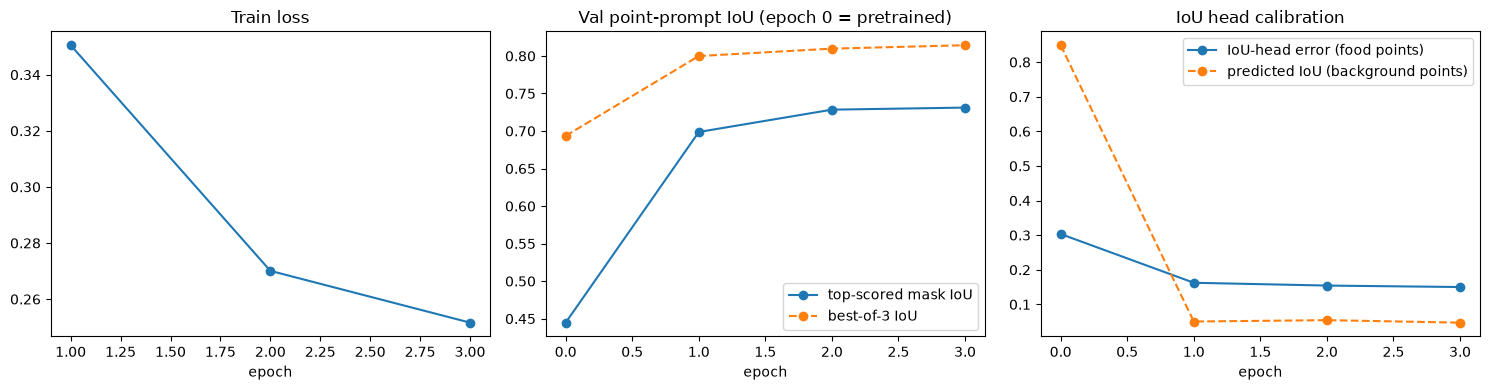

In [10]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hist['epoch'][1:], hist['loss'][1:], marker='o'); axes[0].set_title('Train loss'); axes[0].set_xlabel('epoch')
axes[1].plot(hist['epoch'], hist['top_iou'], marker='o', label='top-scored mask IoU')
axes[1].plot(hist['epoch'], hist['best_iou'], marker='o', linestyle='--', label='best-of-3 IoU')
axes[1].set_title('Val point-prompt IoU (epoch 0 = pretrained)'); axes[1].legend(); axes[1].set_xlabel('epoch')
axes[2].plot(hist['epoch'], hist['iou_mae'], marker='o', label='IoU-head error (food points)')
axes[2].plot(hist['epoch'], hist['neg_pred_iou'], marker='o', linestyle='--', label='predicted IoU (background points)')
axes[2].set_title('IoU head calibration'); axes[2].legend(); axes[2].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(FT_DIR / f'sam2_{MODEL_SIZE}_curves.png', dpi=120); plt.show()

## 8 Test inference with fine-tuned weights

Loads the best fine-tuned prompt encoder + mask decoder into the model and runs the **same default
generator** over the test split. Cached to `outputs/sam2_finetuned_test.pkl` (resumable).

In [11]:
ckpt = torch.load(FT_CKPT, map_location=device, weights_only=False)
sam2_model.sam_prompt_encoder.load_state_dict(ckpt['prompt_encoder'])
sam2_model.sam_mask_decoder.load_state_dict(ckpt['mask_decoder'])
set_trainable(sam2_model, False)
sam2_model.eval()
print('Loaded fine-tuned decoder from epoch', ckpt['epoch'], '| val:', {k: round(v, 4) for k, v in ckpt['val'].items()})

ft_generator = SAM2AutomaticMaskGenerator(sam2_model, output_mode='coco_rle')   # same defaults as the baseline
ft_preds, ft_meta = run_standard(ft_generator, SPLIT, test_ids, FT_CACHE,
                                 f'SAM2.1 hiera_{MODEL_SIZE} AMG (fine-tuned decoder, standard defaults)')
print(f'{len(ft_preds)} images, {ft_meta["sec_per_image"]:.2f}s/img, '
      f'{np.mean([len(p["rle"]) for p in ft_preds.values()]):.1f} masks/img')

Loaded fine-tuned decoder from epoch 3 | val: {'top_iou': 0.7312, 'best_iou': 0.8143, 'iou_mae': 0.1502, 'neg_pred_iou': 0.0473}


SAM2.1 hiera_small AMG (fine-tuned decoder, standard defaults) test:   0%|          | 0/1069 [00:00<?, ?it/s]

1069 images, 1.66s/img, 2.9 masks/img


## 9 Fine-tuned evaluation

In [12]:
ft_m = fc.evaluate(ft_preds, SPLIT, score_thr=SCORE_THR)
ft_result = dict(model=ft_meta['model'], checkpoint=str(FT_CKPT), ft_epoch=ckpt['epoch'],
                 sec_per_image=ft_meta['sec_per_image'], **ft_m)
(OUT_ROOT / 'sam2_finetuned_test_result.json').write_text(json.dumps(ft_result, indent=2))

table = pd.DataFrame({'zero-shot': base_m, 'fine-tuned': ft_m}) if base_preds is not None else pd.DataFrame({'fine-tuned': ft_m})
print(table.to_string(float_format=lambda v: f'{v:.4f}'))

                  zero-shot  fine-tuned
n_images          1069.0000   1069.0000
score_thr            0.0000      0.0000
AP                   0.0448      0.3650
AP50                 0.0701      0.4398
AP75                 0.0415      0.3764
AP_small             0.0016      0.0000
AP_medium            0.0182      0.2000
AP_large             0.0562      0.4111
AR1                  0.0703      0.2039
AR10                 0.1905      0.4601
AR100                0.2043      0.4604
precision@50         0.0668      0.6716
recall@50            0.2762      0.5299
f1@50                0.1075      0.5924
precision@75         0.0481      0.5972
recall@75            0.1988      0.4712
f1@75                0.0774      0.5268
gt_coverage_mean     0.3208      0.5061
gt_coverage_at50     0.2762      0.5299
fg_iou_mean          0.3383      0.6279
fg_iou_pixel         0.3284      0.5870
preds_per_image     15.1590      2.8915


## 10 Visualise test predictions

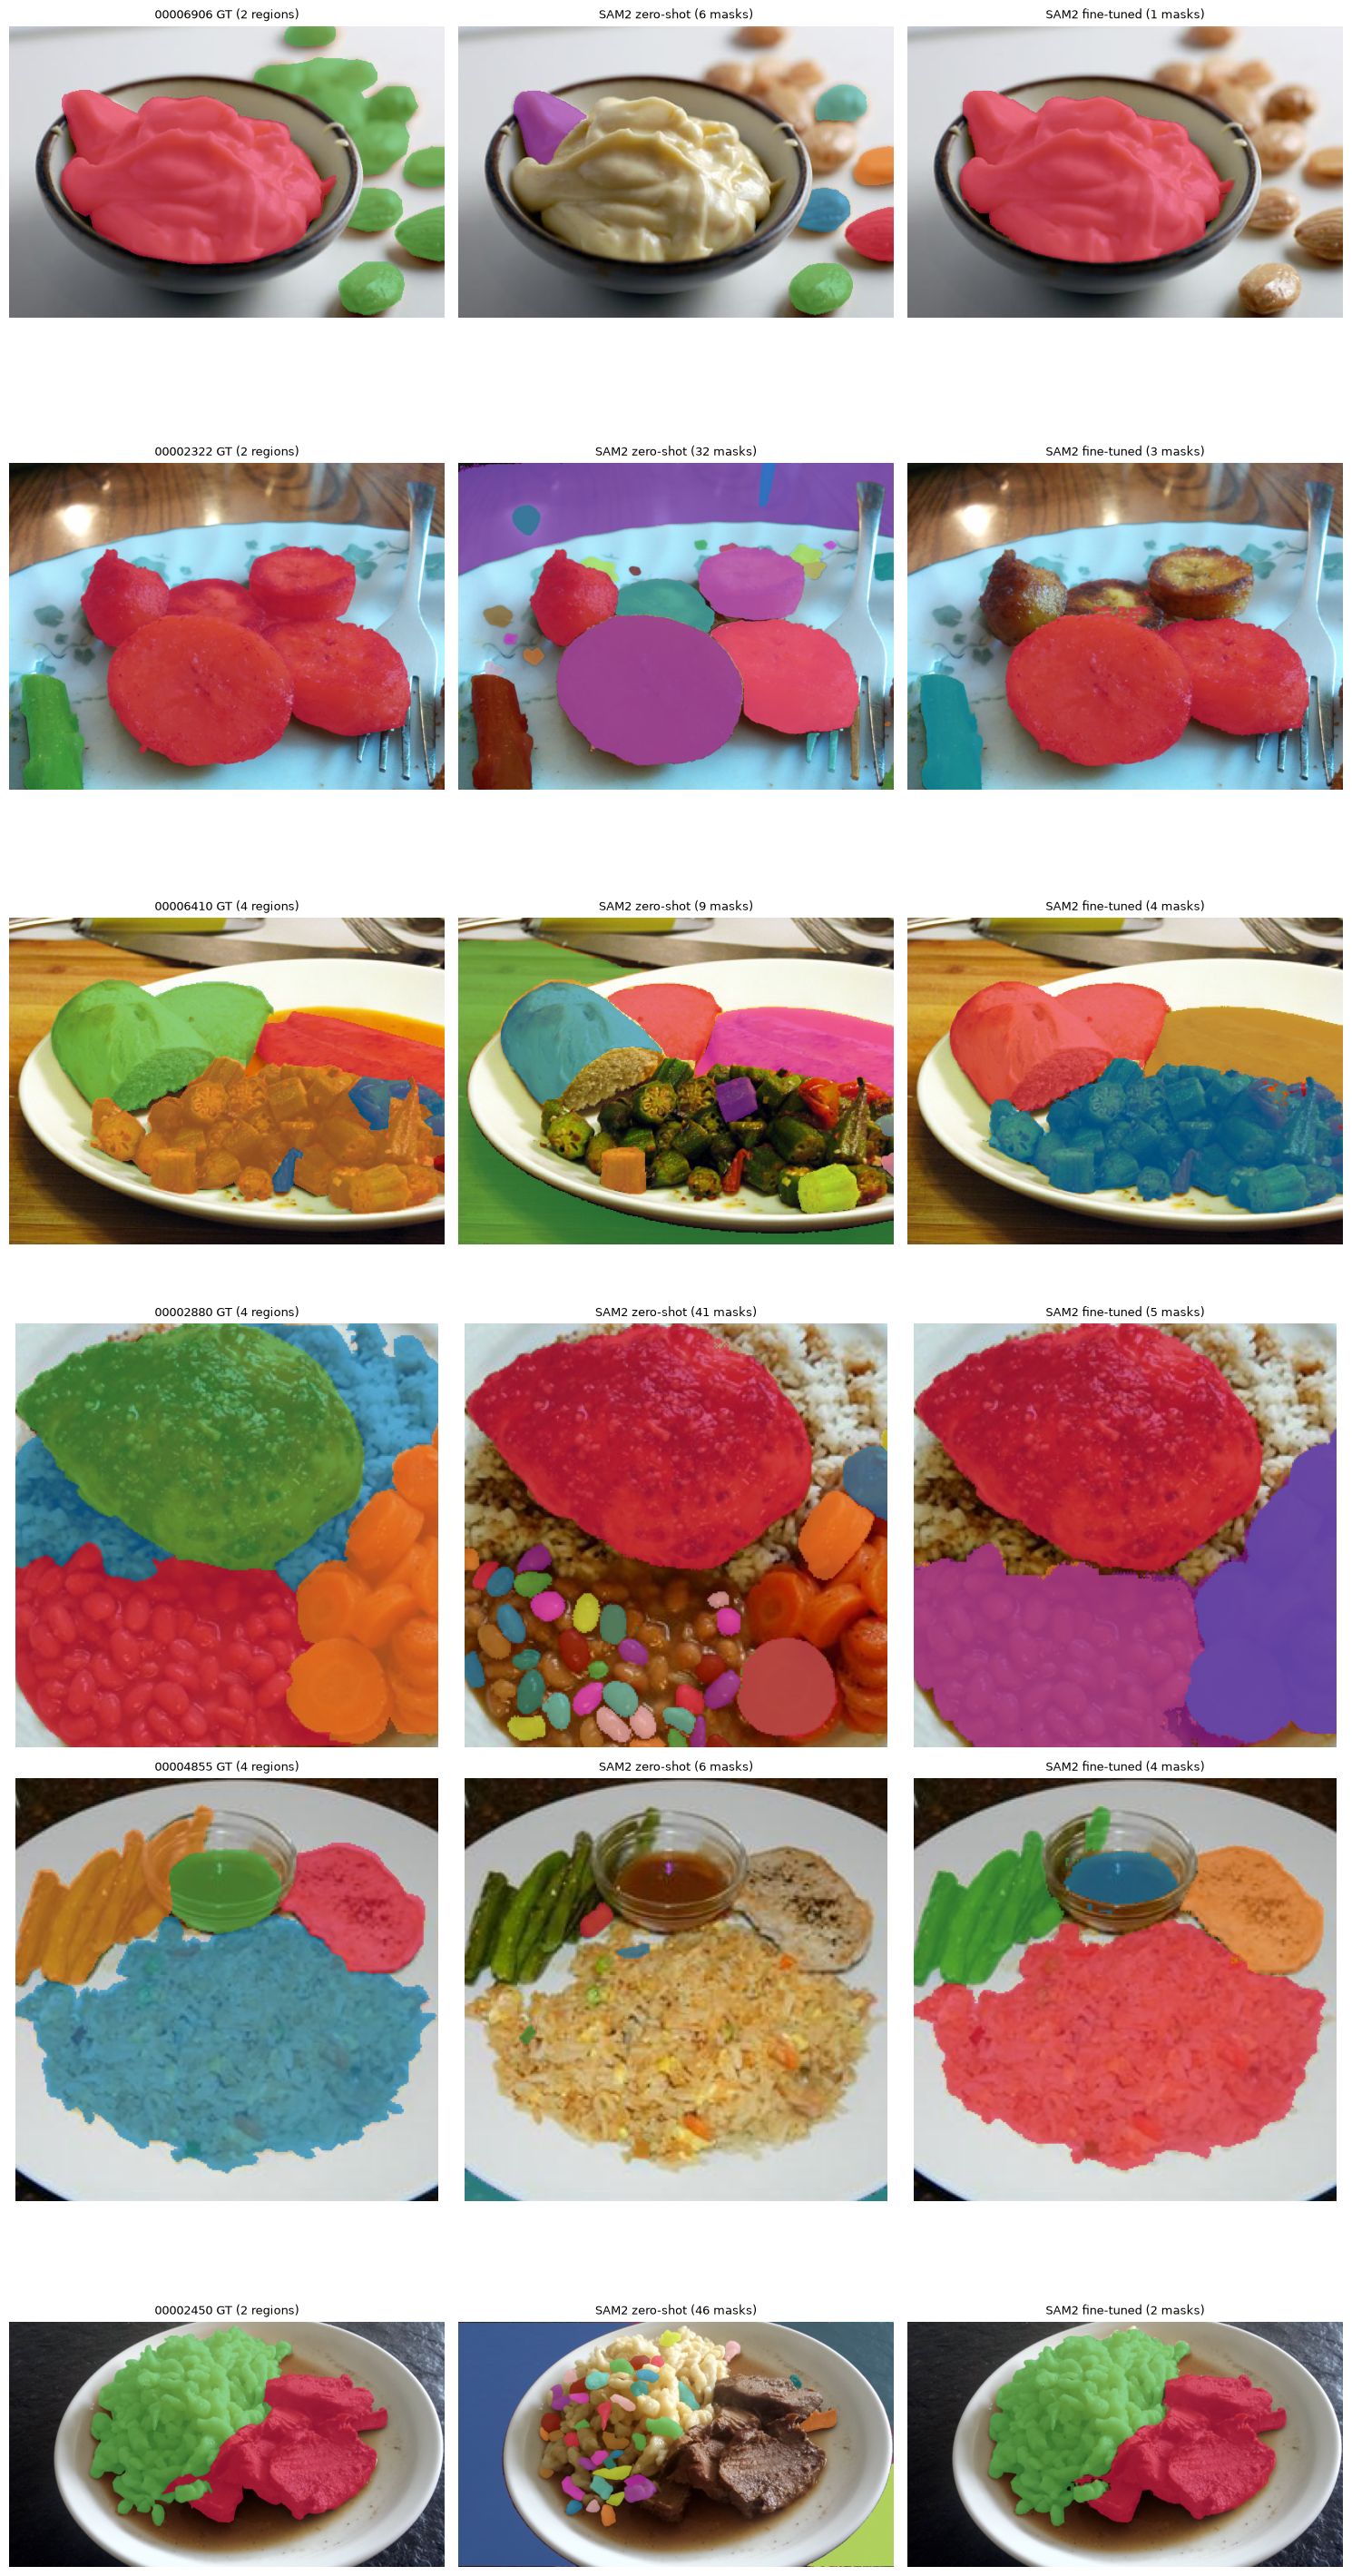

In [13]:
random.seed(SEED)
show = random.sample(list(ft_preds), min(6, len(ft_preds)))
runs = ([('zero-shot', base_preds)] if base_preds is not None else []) + [('fine-tuned', ft_preds)]
fig, axes = plt.subplots(len(show), 1 + len(runs), figsize=(5 * (1 + len(runs)), 5 * len(show)), squeeze=False)
for row, sid in zip(axes, show):
    img = fc.load_rgb(fc.image_path(SPLIT, sid))
    gt = fc.gt_instances(fc.load_label_mask(fc.mask_path(SPLIT, sid)))
    panels = [(fc.overlay(img, gt), f'{sid} GT ({len(gt)} regions)')]
    for name, p in runs:
        pr = fc.decode_kept(p[sid], SCORE_THR)
        panels.append((fc.overlay(img, pr), f'SAM2 {name} ({len(pr)} masks)'))
    for ax, (im, title) in zip(row, panels):
        ax.imshow(im); ax.set_title(title, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()